# ✈️ Flight Club — Deep Learning Phase
## Notebook 01: Data Validation

**Member 1 — Data Pipeline Developer**

**Goal of this notebook:** Check that the dataset is correct and safe to use *before* we build the deep learning model.

**Reason for validating first:**
If the data has problems (missing values, wrong labels, future data mixed into training), the model will learn wrong patterns,
and the results will look good on paper but fail in real use. Finding problems early is cheaper than finding them after training.

In this notebook we:
1. Load the feature-engineered dataset
2. Check the shape, columns and data types
3. Check duplicate rows
4. Check missing values and find the reason for them
5. Check the target distribution
6. Verify the chronological train / validation / test split
7. Identify numerical and categorical features and check for leakage
8. Check for categories that appear in validation/test but not in training

**Important:** This notebook does **not** change the data. It only **inspects and verifies**.
The decisions made here are applied in Notebook 02.

> Every observation in this notebook is based on the output of the code cell above it. We do not assume anything that the data does not show.

### 1. Import libraries and load the dataset

Load `flights_feature_engineered_CORRECTED.csv` and convert the `date` column into a real date type.

- We use **the same file** that our AML models (Logistic Regression and XGBoost) used. If the DL model used different data,
  comparing it with the AML models would not be fair.
- `date` is read from the CSV as text. Converting it to a date type lets us compare dates (for example, "is train before validation?")
  and extract the month.

(In Google Colab, upload the CSV file first.)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_PATH = "flights_feature_engineered_CORRECTED.csv"

df = pd.read_csv(DATA_PATH)
df["date"] = pd.to_datetime(df["date"])

print("Dataset loaded successfully!")

Dataset loaded successfully!


### 2. Dataset shape, columns and data types

Check how many rows and columns there are, look at the first rows, and check the type of each column.

- The **shape** confirms that the whole file was loaded. The previous phase of our project used 327,346 flights, so we expect the same number.
- The **data types** tell us which columns are numbers and which are text. This decides how each column must be preprocessed:
  numbers are scaled, and text categories are converted into indexes.

In [2]:
print("Number of rows   :", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows   : 327346
Number of columns: 24


In [3]:
df.head()

,date,split,delayed,carrier,origin,dest,route,distance,dep_time_sin,dep_time_cos,...,arr_time_sin,arr_time_cos,origin_flights_prev7d,origin_delay_rate_prev7d,carrier_flights_prev7d,carrier_delay_rate_prev7d,dest_flights_prev7d,dest_delay_rate_prev7d,route_flights_prev7d,route_delay_rate_prev7d
0,2013-01-01,train,0.0,UA,EWR,IAH,EWR_IAH,1400,0.980785,1.950903e-01,...,0.821647,-0.569997,0.0,NaN,0.0,NaN,0.0,NaN,0.0,NaN
1,2013-01-01,train,1.0,UA,LGA,IAH,LGA_IAH,1416,0.990866,1.348509e-01,...,0.793353,-0.608761,0.0,NaN,0.0,NaN,0.0,NaN,0.0,NaN
2,2013-01-01,train,1.0,AA,JFK,MIA,JFK_MIA,1089,0.996195,8.715574e-02,...,0.737277,-0.675590,0.0,NaN,0.0,NaN,0.0,NaN,0.0,NaN
3,2013-01-01,train,0.0,B6,JFK,BQN,JFK_BQN,1576,0.997859,6.540313e-02,...,0.414693,-0.909961,0.0,NaN,0.0,NaN,0.0,NaN,0.0,NaN
4,2013-01-01,train,0.0,DL,LGA,ATL,LGA_ATL,762,1.000000,6.123234e-17,...,0.774393,-0.632705,0.0,NaN,0.0,NaN,0.0,NaN,0.0,NaN


In [4]:
# Data type of every column
df.dtypes

date                         datetime64[us]
split                                   str
delayed                             float64
carrier                                 str
origin                                  str
dest                                    str
route                                   str
distance                              int64
dep_time_sin                        float64
dep_time_cos                        float64
weekday_sin                         float64
weekday_cos                         float64
month_sin                           float64
month_cos                           float64
arr_time_sin                        float64
arr_time_cos                        float64
origin_flights_prev7d               float64
origin_delay_rate_prev7d            float64
carrier_flights_prev7d              float64
carrier_delay_rate_prev7d           float64
dest_flights_prev7d                 float64
dest_delay_rate_prev7d              float64
route_flights_prev7d            

**Observation (from the output above):**
- 327,346 rows and 24 columns, which is the same number of flights as the previous phase.
- `carrier`, `origin`, `dest`, `route` and `split` are **text** columns. All other columns (except `date`) are **numbers**.
- `date` and `split` are used to organise the data. They are **not** model inputs.
- `delayed` is the **target** (1 = arrival delay of more than 15 minutes, 0 = otherwise).
- The remaining 21 columns are the input features.

### 3. Duplicate rows

Count rows where *every* column is exactly the same as another row.

Duplicate rows can give some flights extra weight during training. If the same row is in both training and test,
it can also make test results look better than they really are. So we must know how many there are.

In [5]:
num_duplicates = df.duplicated().sum()
print("Number of fully duplicate rows:", num_duplicates)
print("Percentage of data:", round(num_duplicates / len(df) * 100, 4), "%")

Number of fully duplicate rows: 11
Percentage of data: 0.0034 %


In [6]:
# Look at the duplicate rows and their splits
duplicate_rows = df[df.duplicated(keep=False)]
print("Duplicate rows by split:")
print(duplicate_rows["split"].value_counts())
duplicate_rows.head(6)

Duplicate rows by split:
split
test     12
train     8
val       2
Name: count, dtype: int64


,date,split,delayed,carrier,origin,dest,route,distance,dep_time_sin,dep_time_cos,...,arr_time_sin,arr_time_cos,origin_flights_prev7d,origin_delay_rate_prev7d,carrier_flights_prev7d,carrier_delay_rate_prev7d,dest_flights_prev7d,dest_delay_rate_prev7d,route_flights_prev7d,route_delay_rate_prev7d
172,2013-01-01,train,0.0,UA,EWR,MIA,EWR_MIA,1085,0.688355,-0.725374,...,-0.113203,-0.993572,0.0,NaN,0.0,NaN,0.0,NaN,0.0,NaN
180,2013-01-01,train,0.0,UA,EWR,MIA,EWR_MIA,1085,0.688355,-0.725374,...,-0.113203,-0.993572,0.0,NaN,0.0,NaN,0.0,NaN,0.0,NaN
52364,2013-10-29,val,0.0,DL,JFK,ATL,JFK_ATL,760,0.793353,-0.608761,...,0.279829,-0.960050,2047.0,0.134343,927.0,0.134844,326.0,0.202454,37.0,0.054054
52372,2013-10-29,val,0.0,DL,JFK,ATL,JFK_ATL,760,0.793353,-0.608761,...,0.279829,-0.960050,2047.0,0.134343,927.0,0.134844,326.0,0.202454,37.0,0.054054
58550,2013-11-05,test,0.0,DL,JFK,ATL,JFK_ATL,760,0.991445,-0.130526,...,0.704015,-0.710185,1994.0,0.136409,906.0,0.084989,318.0,0.125786,35.0,0.057143
58552,2013-11-05,test,0.0,DL,JFK,ATL,JFK_ATL,760,0.991445,-0.130526,...,0.704015,-0.710185,1994.0,0.136409,906.0,0.084989,318.0,0.125786,35.0,0.057143


**Observation (from the output above):**
- Only 11 rows are duplicates, which is 0.0034% of the data.
- A duplicate row is identical in **every** column, **including `date` and `split`**, so both copies are always in the **same split**.
  A duplicate never crosses from training into test, so duplicates cannot leak test information into training.

**Can we tell whether they are mistakes or two real flights?**
No. This file does not contain the flight number or the aircraft tail number (they were removed during feature engineering),
so we cannot check. We do **not** assume either way.

**Decision: keep them.**
1. 11 rows out of 327,346 is too few to change the model.
2. Our AML models were trained on all 327,346 rows. Keeping the same rows makes the comparison between the AML and DL models fair.
3. They cannot cause leakage between splits (shown above).

### 4. Missing values

Count the missing values (`NaN`) in each column.

A neural network cannot do calculations with `NaN`. One `NaN` in the input makes the output `NaN`, and training breaks.
Before deciding how to fix missing values, we first need to know **which** columns have them and the **reason**.

In [7]:
missing = df.isna().sum()
missing = missing[missing > 0]

print("Columns with missing values:")
print(missing)

Columns with missing values:
origin_delay_rate_prev7d     1759
carrier_delay_rate_prev7d    1768
dest_delay_rate_prev7d       1840
route_delay_rate_prev7d      2015
dtype: int64


Only the four **historical delay rate** columns have missing values. Let us find the reason.

A delay rate is calculated as: *delayed flights in the previous 7 days ÷ total flights in the previous 7 days*.

**Our idea to test:** if there were **0 flights** in the previous 7 days, the rate would be 0 ÷ 0, which cannot be calculated.
We check this with the matching count column (`..._flights_prev7d`).

In [8]:
for group in ["origin", "carrier", "dest", "route"]:
    rate_col = group + "_delay_rate_prev7d"
    count_col = group + "_flights_prev7d"

    missing_rows = df[df[rate_col].isna()]
    max_count = missing_rows[count_col].max()

    print(f"{rate_col}: {len(missing_rows)} missing, "
          f"highest previous-7-day flight count in these rows = {max_count}")

origin_delay_rate_prev7d: 1759 missing, highest previous-7-day flight count in these rows = 0.0
carrier_delay_rate_prev7d: 1768 missing, highest previous-7-day flight count in these rows = 0.0
dest_delay_rate_prev7d: 1840 missing, highest previous-7-day flight count in these rows = 0.0
route_delay_rate_prev7d: 2015 missing, highest previous-7-day flight count in these rows = 0.0


In [9]:
# Where do the missing values occur? (split and date range)
for group in ["origin", "carrier", "dest", "route"]:
    rate_col = group + "_delay_rate_prev7d"
    missing_rows = df[df[rate_col].isna()]
    print(f"{rate_col}:")
    print("   rows per split:", missing_rows["split"].value_counts().to_dict())
    print("   dates        :", missing_rows["date"].min().date(), "to", missing_rows["date"].max().date())

origin_delay_rate_prev7d:
   rows per split: {'train': 1759}
   dates        : 2013-01-01 to 2013-01-02
carrier_delay_rate_prev7d:
   rows per split: {'train': 1767, 'test': 1}
   dates        : 2013-01-01 to 2013-11-03
dest_delay_rate_prev7d:
   rows per split: {'train': 1812, 'test': 20, 'val': 8}
   dates        : 2013-01-01 to 2013-12-22
route_delay_rate_prev7d:
   rows per split: {'train': 1918, 'test': 62, 'val': 35}
   dates        : 2013-01-01 to 2013-12-29


**Observation (from the output above):**
- In **every** row with a missing delay rate, the previous-7-day flight count is **0**. Our idea is confirmed:
  the values are missing because there was no past data to calculate them from. They are not errors.
- For `origin`, all missing values are on **1–2 January**, the start of the dataset, when there is no earlier week to look back at.
- For `carrier`, `dest` and `route`, most missing values are in training, but a few are in validation and test,
  for example a route with no flights in the week before.
- The target column `delayed` has **no** missing values.

**Decision (applied in Notebook 02):** fill these values with the **median of the training data only**.
- We do not **drop** these rows. We would lose real flights, including some test flights that the model must be able to predict.
- We do not lose information by filling. The matching count column is still **0**, so the model can still see that
  "there was no history for this flight".

### 5. Target distribution

Count how many flights are on time (0) and how many are delayed (1).

If one class is much bigger than the other (an **imbalanced** dataset), a model can get high accuracy by always
predicting the bigger class. We need to know this to choose the right evaluation metrics.

In [10]:
target_counts = df["delayed"].value_counts().sort_index()
target_percent = df["delayed"].value_counts(normalize=True).sort_index() * 100

print("Unique target values:", sorted(df["delayed"].unique()))
print()
print(pd.DataFrame({"count": target_counts, "percent": target_percent.round(2)}))

Unique target values: [np.float64(0.0), np.float64(1.0)]

          count  percent
delayed                 
0.0      249716    76.29
1.0       77630    23.71


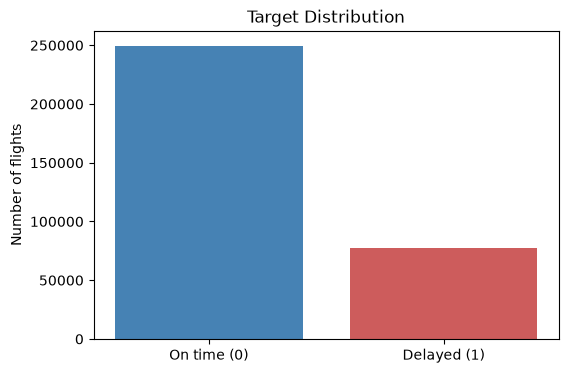

In [11]:
plt.figure(figsize=(6, 4))
plt.bar(["On time (0)", "Delayed (1)"], target_counts.values, color=["steelblue", "indianred"])
plt.title("Target Distribution")
plt.ylabel("Number of flights")
plt.show()

In [12]:
# Proof that accuracy is misleading:
# a "model" that ALWAYS predicts "on time" (0), without learning anything
test_df = df[df["split"] == "test"]
always_zero_accuracy = (test_df["delayed"] == 0).mean()

print("Accuracy on test if we always predict 'on time':", round(always_zero_accuracy * 100, 2), "%")
print("Delayed flights this 'model' catches          : 0")

Accuracy on test if we always predict 'on time': 75.01 %
Delayed flights this 'model' catches          : 0


**Observation (from the output above):**
- The target has only two values, 0 and 1, so this is a **binary classification** problem.
- 76.29% of flights are on time and 23.71% are delayed, so the dataset is **imbalanced**.
- A useless model that always says "on time" still gets about **75% accuracy** on the test set while catching **zero** delayed flights.

**Conclusion:** Accuracy alone is misleading for this problem. The model must also be judged with metrics that focus on the delayed class,
such as **recall, precision, F1 score, ROC-AUC and PR-AUC**.

### 6. Verify the chronological split

The data is split by **time**, not randomly:
- **Train:** January – August
- **Validation:** September – October
- **Test:** November – December

**Time-based split instead of a random split:**
- In real life we predict **future** flights using **past** data. A time-based split copies this.
- With a random split, the training set would contain flights from November and December. The model would learn from
  "the future" and the test score would be unrealistically high. This is a type of **data leakage**.
- Our historical features (`..._prev7d`) are calculated from the previous 7 days. With a random split, a training flight and a
  test flight from the same week would share information.

**Reusing the existing `split` column:**
The AML models used this exact split. If we made a new split, the DL model would be tested on different flights and the comparison would not be fair.

**Purpose of the three sets:**
- **Train:** the model learns from it.
- **Validation:** used to choose settings (number of epochs, threshold, and so on) and to stop training at the right time.
- **Test:** used **once** at the end to report the final, unbiased result.

In [13]:
split_summary = df.groupby("split").agg(
    flights=("delayed", "count"),
    start_date=("date", "min"),
    end_date=("date", "max"),
    delay_rate=("delayed", "mean"),
)
split_summary = split_summary.loc[["train", "val", "test"]]
split_summary

,flights,start_date,end_date,delay_rate
split,,,,
train,217727,2013-01-01,2013-08-31,0.256123
val,55628,2013-09-01,2013-10-31,0.150518
test,53991,2013-11-01,2013-12-31,0.249894


In [14]:
train_df = df[df["split"] == "train"]
val_df = df[df["split"] == "val"]
test_df = df[df["split"] == "test"]

# Check 1: the periods do not overlap (train ends before validation starts, and so on)
assert train_df["date"].max() < val_df["date"].min()
assert val_df["date"].max() < test_df["date"].min()

# Check 2: every row belongs to exactly one split
assert len(train_df) + len(val_df) + len(test_df) == len(df)

print("Chronological split verified. No overlap between train, validation and test.")

Chronological split verified. No overlap between train, validation and test.


**`assert` statements:** `assert` stops the notebook with an error if the condition is false.
Because the cell printed the success message, we have **proof** (not just a belief) that the splits are in the correct time order and do not overlap.

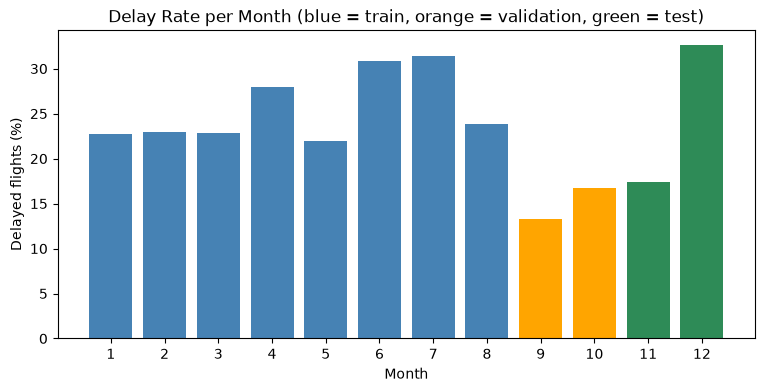

date
1     22.7
2     22.9
3     22.8
4     27.9
5     22.0
6     30.8
7     31.5
8     23.8
9     13.2
10    16.8
11    17.4
12    32.6
Name: delayed, dtype: float64


In [15]:
# Delay rate for each month, to see how it changes over time
monthly_delay = df.groupby(df["date"].dt.month)["delayed"].mean() * 100
month_split = df.groupby(df["date"].dt.month)["split"].first()

colors = {"train": "steelblue", "val": "orange", "test": "seagreen"}

plt.figure(figsize=(9, 4))
plt.bar(monthly_delay.index, monthly_delay.values, color=[colors[s] for s in month_split])
plt.title("Delay Rate per Month (blue = train, orange = validation, green = test)")
plt.xlabel("Month")
plt.ylabel("Delayed flights (%)")
plt.xticks(range(1, 13))
plt.show()

print(monthly_delay.round(1))

**Observation (from the output above):**
- The splits are in the correct time order and do not overlap.
- The delay rate changes over time: about 25.6% in train, about **15.1% in validation** and about 25.0% in test.
  The monthly chart shows that September and October have the lowest delay rates of the year.

**Importance:**
The validation period has noticeably fewer delays than the training period. This is called a **distribution shift**.
The model must work in months that behave differently from the training months, and a time-based split tests exactly that.
When we look at validation results later, we must remember that this period has fewer delays.

*Note: this dataset does not contain weather or holiday information, so we report the change but do not claim a cause for it.*

### 7. Identify numerical and categorical features and check for leakage

We use the **same 21 features** as the AML models, so the comparison is fair.

**Categorical features (4):** `carrier`, `origin`, `dest`, `route`
- These are **labels**, not amounts. For example, "UA" is not bigger or smaller than "AA".
- In the DL model, these will go into **embedding layers**.

**Numerical features (17):** `distance`, the sine/cosine time features and the historical delay statistics.
- These are real amounts, so they can be scaled and given to the network directly.

**Leakage:** Leakage means using information that would **not be known at prediction time**,
for example the actual departure delay. Our project predicts **before departure**, so any column that is only known after
the flight must not be an input. We check this with code.

In [16]:
categorical_features = ["carrier", "origin", "dest", "route"]

numerical_features = [
    "distance",
    "dep_time_sin", "dep_time_cos",
    "weekday_sin", "weekday_cos",
    "month_sin", "month_cos",
    "arr_time_sin", "arr_time_cos",
    "origin_delay_rate_prev7d", "origin_flights_prev7d",
    "carrier_delay_rate_prev7d", "carrier_flights_prev7d",
    "dest_delay_rate_prev7d", "dest_flights_prev7d",
    "route_delay_rate_prev7d", "route_flights_prev7d",
]

print("Categorical features:", len(categorical_features))
print("Numerical features  :", len(numerical_features))

Categorical features: 4
Numerical features  : 17


In [17]:
# Check that all 24 columns are accounted for: 21 features + date + split + delayed
all_features = categorical_features + numerical_features
other_columns = [col for col in df.columns if col not in all_features]
print("Columns that are NOT features:", other_columns)

# Every feature must exist in the dataset
for col in all_features:
    assert col in df.columns

# Leakage check: these columns must never be model inputs
leakage_columns = ["delayed", "date", "split", "arr_delay", "dep_delay",
                   "dep_time", "arr_time", "air_time"]
for col in leakage_columns:
    assert col not in all_features

# Actual-outcome columns should not even be in the file
print("Actual-outcome columns present in the file:",
      [col for col in ["arr_delay", "dep_delay", "dep_time", "arr_time", "air_time"] if col in df.columns])

print("Leakage check passed.")

Columns that are NOT features: ['date', 'split', 'delayed']
Actual-outcome columns present in the file: []
Leakage check passed.


**Observation (from the output above):**
- The only columns that are not features are `date`, `split` and `delayed`, as expected.
- The actual-outcome columns (`arr_delay`, `dep_delay`, `dep_time`, `arr_time`, `air_time`) are **not in the file at all**.
  They were removed during feature engineering, and we have double-checked this.
- So the model only gets information that is available **before departure**.

**Sine/cosine time features** (done in feature engineering):
Time is circular: 23:00 and 00:00 are 1 hour apart, but as plain numbers (23 and 0) they look far apart.
Sine and cosine put the values on a circle, so times that are close in real life are also close as numbers.

### 8. Unique categories and unseen categories

For each categorical feature, check whether validation or test contain categories that **never appear in training**.

An embedding layer learns one vector for each category it sees **during training**. If a new airport appears only in the test set,
the model has no vector for it, and the code would crash or give a wrong result. We need to know if this happens so we can plan for it.

In [18]:
rows = []
for col in categorical_features:
    train_categories = set(train_df[col].unique())

    unseen_val = ~val_df[col].isin(train_categories)
    unseen_test = ~test_df[col].isin(train_categories)

    rows.append({
        "feature": col,
        "categories_in_train": len(train_categories),
        "unseen_rows_in_val": unseen_val.sum(),
        "unseen_rows_in_test": unseen_test.sum(),
    })

pd.DataFrame(rows)

,feature,categories_in_train,unseen_rows_in_val,unseen_rows_in_test
0,carrier,16,0,0
1,origin,3,0,0
2,dest,102,51,57
3,route,218,54,61


In [19]:
# Which destinations are new, and when do they first appear in the data?
train_dests = set(train_df["dest"].unique())
new_dests = sorted((set(val_df["dest"]) | set(test_df["dest"])) - train_dests)

for dest in new_dests:
    dest_rows = df[df["dest"] == dest]
    print(f"{dest}: first flight on {dest_rows['date'].min().date()}, total flights = {len(dest_rows)}")

ILM: first flight on 2013-09-07, total flights = 107
LEX: first flight on 2013-11-24, total flights = 1


In [20]:
# How many routes are new?
train_routes = set(train_df["route"].unique())
new_routes = sorted((set(val_df["route"]) | set(test_df["route"])) - train_routes)
print("Number of new routes:", len(new_routes))
print("New routes:", new_routes)

Number of new routes: 5
New routes: ['EWR_SBN', 'JFK_JAC', 'JFK_STL', 'LGA_ILM', 'LGA_LEX']


**Observation (from the output above):**
- `carrier` and `origin` have **no** unseen categories.
- The destinations **ILM** and **LEX** do not appear at all in the training months. The output shows the date of the first flight to each one.
- A few routes (shown above) also appear only after the training period.
- Compared with the size of validation (55,628) and test (53,991), these are very few rows, but the code must still handle them.

**Decision (applied in Notebook 02):** reserve **index 0 for "unknown"** categories.
Any category that was not seen in training is mapped to 0, so the model can still make a prediction for that flight instead of crashing.

### 9. Summary

| Check | Result (from code output) | Decision for Notebook 02 |
|---|---|---|
| Shape | 327,346 rows × 24 columns | Use all rows |
| Duplicate rows | 11 rows (0.0034%), never across splits | Keep, same rows as the AML models |
| Missing values | Only the 4 delay-rate columns, always when the past 7-day count = 0 | Fill with the **train** median |
| Target | Binary 0/1, 23.71% delayed | Imbalanced, so don't rely on accuracy |
| Chronological split | Train Jan–Aug, Val Sep–Oct, Test Nov–Dec, no overlap | Reuse the existing split |
| Distribution shift | Validation delay rate (15.1%) is lower than train (25.6%) | Keep in mind when reading results |
| Features | 17 numerical + 4 categorical, no leakage columns | Scale numbers, use embeddings for categories |
| Unseen categories | Some destinations/routes only in val/test | Map them to index 0 ("unknown") |

The dataset is valid and ready for preprocessing in **Notebook 02**.